In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

In [21]:
# Load dataset
df = pd.read_csv("heart_disease.csv")

# Remove extra spaces from column names
df.columns 

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'condition'],
      dtype='object')

In [22]:
df.replace("?", np.nan, inplace=True)
df.dropna(inplace=True)

In [23]:
for col in ["age", "trestbps", "chol", "thalach", "oldpeak"]:
    df[col] = pd.cut(df[col], bins=2, labels=False)

In [24]:
df.dropna(inplace=True)
X = df.drop("condition", axis=1)
y = df["condition"]


In [25]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

train = X_train.copy()
train["condition"] = y_train

In [26]:
edges = [(col, "condition") for col in X.columns]
model = DiscreteBayesianNetwork(edges)

model.add_cpds(*BayesianEstimator(
    model, train
).get_parameters(prior_type="BDeu"))

C:\Users\ASUS\AppData\Local\Temp\ipykernel_7032\906117176.py:4: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  model.add_cpds(*BayesianEstimator(


In [27]:
infer = VariableElimination(model)
pred = []

for _, row in X_test.iterrows():
    result = infer.map_query(
        variables=["condition"],
        evidence=row.to_dict(),
        show_progress=False
    )
    pred.append(result["condition"])

print("Accuracy:", accuracy_score(y_test, pred) * 100)


Accuracy: 56.666666666666664


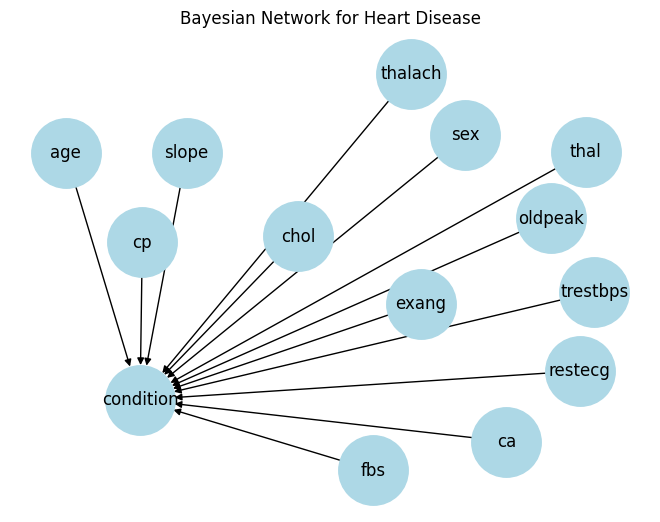

In [28]:
# Display Bayesian Network
G = nx.DiGraph(edges)

nx.draw(
    G, with_labels=True, node_color="lightblue",
    node_size=2500, arrows=True
)

plt.title("Bayesian Network for Heart Disease")
plt.show()
